# Classificação de Objetos Celestes (Stellar Classification — SDSS17)

## Contexto do problema

O dataset **Stellar Classification** (Kaggle: `fedesoriano/stellar-classification-dataset-sdss17`) reúne observações do **Sloan Digital Sky Survey (SDSS)**, um dos maiores levantamentos astronômicos já realizados. Cada registro descreve um objeto celeste por meio de medições fotométricas (magnitudes nas bandas u, g, r, i, z), posição no céu (alpha, delta) e desvio para o vermelho (redshift).

**Objetivo de negócio:** classificar automaticamente cada objeto em uma de três categorias — `GALAXY` (galáxia), `QSO` (quasi-stellar object / quasar) ou `STAR` (estrela) — a partir dessas medições. Na prática, isso reduz o esforço manual de triagem em levantamentos astronômicos e apoia a priorização de observações para acompanhamento espectroscópico.

**Tipo de problema:** classificação multiclasse (3 classes).

## Dicionário de dados

| Coluna | Tipo | Significado |
|---|---|---|
| `alpha` | float | Ascensão reta (coordenada celestial, em graus) |
| `delta` | float | Declinação (coordenada celestial, em graus) |
| `u` | float | Magnitude na banda ultravioleta |
| `g` | float | Magnitude na banda verde |
| `r` | float | Magnitude na banda vermelha |
| `i` | float | Magnitude na banda infravermelha próxima |
| `z` | float | Magnitude na banda infravermelha |
| `redshift` | float | Desvio para o vermelho (indica distância/velocidade de afastamento) |
| `class` | str | **Variável alvo**: GALAXY, QSO ou STAR |

**Colunas removidas por serem identificadores (não preditivas):** `obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `spec_obj_ID`, `plate`, `MJD`, `fiber_ID`. Mantê-las introduziria ruído e risco de vazamento.

**Feature engineering:** será criada a variável categórica `faixa_redshift` (baixo / médio / alto) a partir de `redshift`, para exercitar o `OneHotEncoder` no pipeline e permitir que o modelo trate faixas de redshift de forma discreta.

In [4]:
# --- Imports ---
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 77

# --- Descoberta da raiz do projeto ---
def encontrar_raiz_projeto(inicio: Path) -> Path:
    atual = inicio.resolve()
    for pai in [atual, *atual.parents]:
        if (pai / "data" / "star_classification.csv").exists():
            return pai
    raise FileNotFoundError(
        "Não encontrei data/star_classification.csv subindo a partir de "
        f"{inicio.resolve()}. Verifique se o arquivo existe e se a pasta "
        "do projeto está aberta no VS Code."
    )

RAIZ = encontrar_raiz_projeto(Path.cwd())
CAMINHO_DATASET = RAIZ / "data" / "star_classification.csv"
CAMINHO_MODELO = RAIZ / "models" / "pipeline_rede_neural.joblib"

print(f"Raiz do projeto: {RAIZ}")
print(f"Dataset: {CAMINHO_DATASET} (existe: {CAMINHO_DATASET.exists()})")
print(f"Modelo será salvo em: {CAMINHO_MODELO}")

# --- Carga ---
df_raw = pd.read_csv(CAMINHO_DATASET)
print(f"\nShape original: {df_raw.shape}")
print(f"Colunas: {list(df_raw.columns)}")
df_raw.head()

Raiz do projeto: /home/osyapov/Documents/at2-rn-mlp-deploy-api
Dataset: /home/osyapov/Documents/at2-rn-mlp-deploy-api/data/star_classification.csv (existe: True)
Modelo será salvo em: /home/osyapov/Documents/at2-rn-mlp-deploy-api/models/pipeline_rede_neural.joblib

Shape original: (100000, 18)
Colunas: ['o"obj_ID"', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']


,"o""obj_ID""",alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


Registros: 100000 | Colunas: 18

Valores nulos por coluna:
o"obj_ID"      0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

Distribuição da variável alvo 'class':
        contagem  percentual (%)
class                           
GALAXY     59445           59.44
STAR       21594           21.59
QSO        18961           18.96


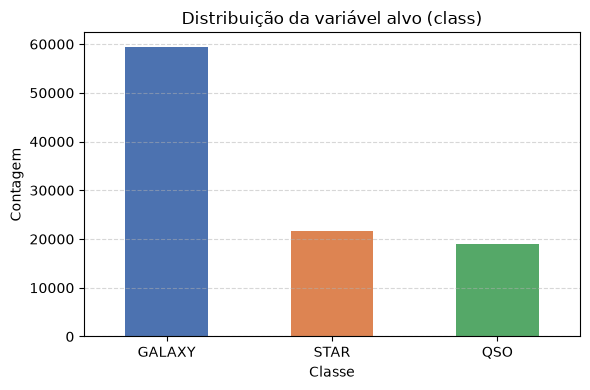

In [5]:
# Verificação de dimensionalidade e nulos
print(f"Registros: {df_raw.shape[0]} | Colunas: {df_raw.shape[1]}")
print("\nValores nulos por coluna:")
print(df_raw.isnull().sum())

# Distribuição da variável alvo (checagem de desbalanceamento)
print("\nDistribuição da variável alvo 'class':")
contagem = df_raw["class"].value_counts()
percentual = df_raw["class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"contagem": contagem, "percentual (%)": percentual.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
contagem.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Distribuição da variável alvo (class)")
ax.set_xlabel("Classe")
ax.set_ylabel("Contagem")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Registros: 100000 | Colunas: 18

Valores nulos por coluna:
o"obj_ID"      0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

Distribuição da variável alvo 'class':
        contagem  percentual (%)
class                           
GALAXY     59445           59.44
STAR       21594           21.59
QSO        18961           18.96


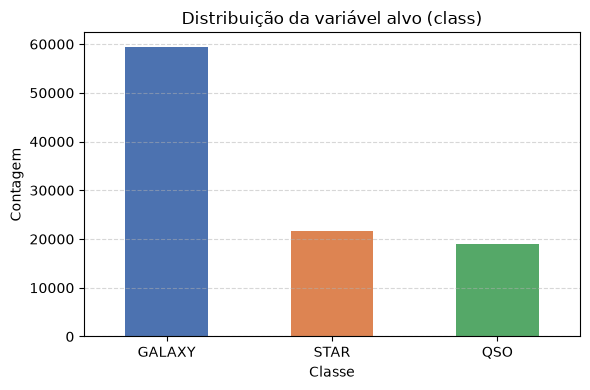

In [6]:
# Dimensionalidade e nulos
print(f"Registros: {df_raw.shape[0]} | Colunas: {df_raw.shape[1]}")
print("\nValores nulos por coluna:")
print(df_raw.isnull().sum())

# Distribuição da variável alvo
print("\nDistribuição da variável alvo 'class':")
contagem = df_raw["class"].value_counts()
percentual = df_raw["class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"contagem": contagem, "percentual (%)": percentual.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
contagem.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Distribuição da variável alvo (class)")
ax.set_xlabel("Classe")
ax.set_ylabel("Contagem")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

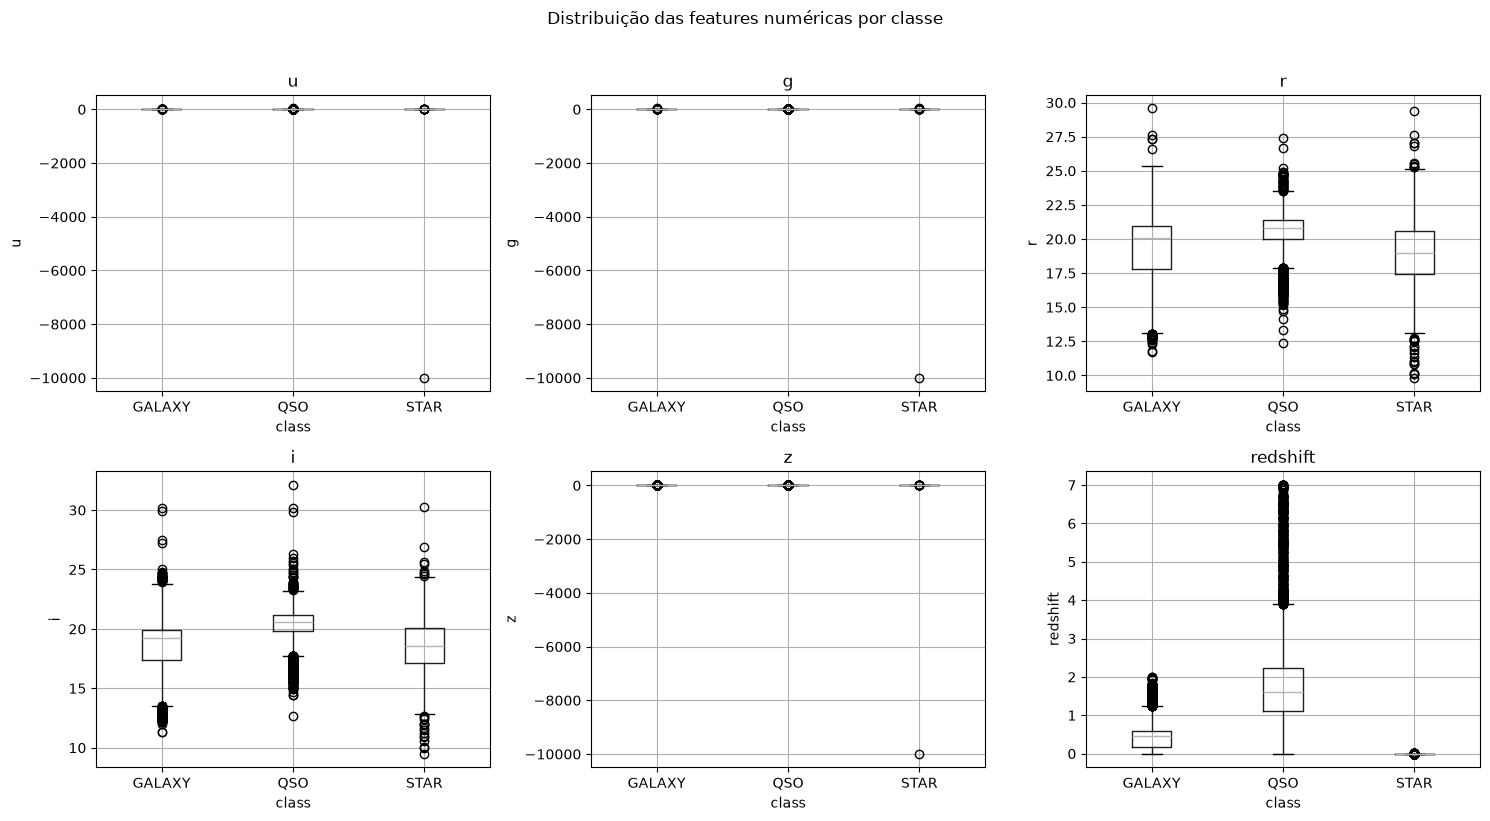

In [7]:
# Boxplots das magnitudes por classe (features críticas)
features_numericas = ["u", "g", "r", "i", "z", "redshift"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(features_numericas):
    df_raw.boxplot(column=col, by="class", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("class")
    axes[i].set_ylabel(col)

plt.suptitle("Distribuição das features numéricas por classe", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# Cria a categórica derivada a partir do redshift
df = df_raw.copy()

df["faixa_redshift"] = pd.cut(
    df["redshift"],
    bins=[-np.inf, 0.1, 0.5, np.inf],
    labels=["baixo", "medio", "alto"],
)

print("Distribuição de faixa_redshift:")
print(df["faixa_redshift"].value_counts(dropna=False))

df[["redshift", "faixa_redshift"]].head()

Distribuição de faixa_redshift:
faixa_redshift
alto     43241
baixo    30296
medio    26463
Name: count, dtype: int64


,redshift,faixa_redshift
0,0.634794,alto
1,0.779136,alto
2,0.644195,alto
3,0.932346,alto
4,0.116123,medio


In [9]:
# Colunas que entram no modelo
colunas_numericas = ["alpha", "delta", "u", "g", "r", "i", "z", "redshift"]
colunas_categoricas = ["faixa_redshift"]
coluna_alvo = "class"

X = df[colunas_numericas + colunas_categoricas]
y = df[coluna_alvo]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print("\nDistribuição do target no treino:")
print(y_train.value_counts(normalize=True).round(4))

Treino: (80000, 9) | Teste: (20000, 9)

Distribuição do target no treino:
class
GALAXY    0.5944
STAR      0.2159
QSO       0.1896
Name: proportion, dtype: float64


In [10]:
# Pré-processamento: escala numéricas + one-hot nas categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), colunas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
    ]
)

# Pipeline completo: pré-processamento + rede neural
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classificador",
            MLPClassifier(
                hidden_layer_sizes=(128, 64, 32),
                activation="relu",
                solver="adam",
                learning_rate_init=0.001,
                max_iter=500,
                random_state=RANDOM_STATE,
                early_stopping=True,
                n_iter_no_change=15,
            ),
        ),
    ]
)

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0

In [11]:
import time

t_inicio = time.perf_counter()
pipeline.fit(X_train, y_train)
t_fim = time.perf_counter()

print(f"Treinamento concluído em {t_fim - t_inicio:.2f} s")
print(f"Épocas executadas: {pipeline.named_steps['classificador'].n_iter_}")

Treinamento concluído em 102.28 s
Épocas executadas: 52


Acurácia global: 97.32%
Matthews Correlation Coefficient (MCC): 0.9526

Relatório de métricas por classe:
              precision    recall  f1-score   support

      GALAXY     0.9773    0.9777    0.9775     11889
         QSO     0.9621    0.9296    0.9455      3792
        STAR     0.9716    0.9993    0.9853      4319

    accuracy                         0.9732     20000
   macro avg     0.9703    0.9689    0.9694     20000
weighted avg     0.9732    0.9732    0.9731     20000



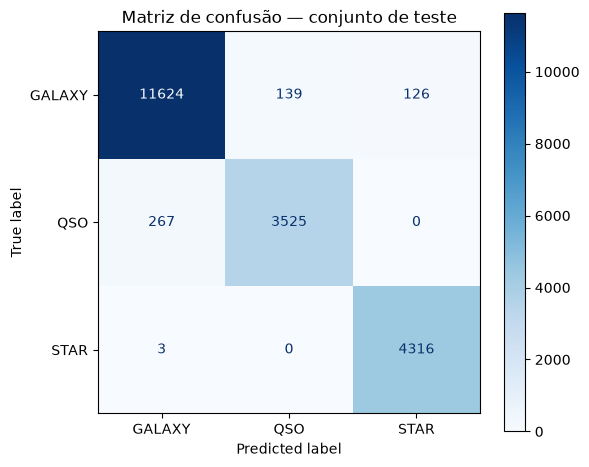

In [12]:
y_pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

print(f"Acurácia global: {acc * 100:.2f}%")
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")
print("\nRelatório de métricas por classe:")
print(classification_report(y_test, y_pred, digits=4))

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusão — conjunto de teste")
plt.tight_layout()
plt.show()

In [13]:
CAMINHO_MODELO.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, CAMINHO_MODELO)
print(f"Pipeline serializado em: {CAMINHO_MODELO}")
print(f"Tamanho do arquivo: {CAMINHO_MODELO.stat().st_size / 1024:.2f} KB")

Pipeline serializado em: /home/osyapov/Documents/at2-rn-mlp-deploy-api/models/pipeline_rede_neural.joblib
Tamanho do arquivo: 292.55 KB


In [14]:
# Simula o que a API fará no startup: carregar o .joblib e inferir
pipeline_carregado = joblib.load(CAMINHO_MODELO)

amostra = X_test.iloc[[0]]
pred = pipeline_carregado.predict(amostra)[0]
proba = pipeline_carregado.predict_proba(amostra)[0]

print(f"Amostra de teste:\n{amostra.to_dict(orient='records')[0]}")
print(f"\nClasse prevista: {pred}")
print(f"Probabilidades por classe: {dict(zip(pipeline_carregado.classes_, proba.round(4)))}")
print(f"Score de confiança (max proba): {proba.max():.4f}")

Amostra de teste:
{'alpha': 235.757615838292, 'delta': 27.6564111550441, 'u': 18.78082, 'g': 17.87685, 'r': 17.61213, 'i': 17.54794, 'z': 17.46591, 'redshift': -0.0003992696, 'faixa_redshift': 'baixo'}

Classe prevista: STAR
Probabilidades por classe: {np.str_('GALAXY'): np.float64(0.0564), np.str_('QSO'): np.float64(0.0001), np.str_('STAR'): np.float64(0.9435)}
Score de confiança (max proba): 0.9435
